In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from google.colab import files

Загружаем сырые данные по заказам: order_id, order_value, customer_state (без агрегации — нужны сырые наблюдения для статистического теста).

In [2]:
uploaded = files.upload()

Saving state_aov_users.csv to state_aov_users.csv


In [3]:
df = pd.read_csv('state_aov_users.csv')

RJ, SP, MG - топ 3 по количеству заказов

PB - самый большой AOV

Отбираем 4 штата для сравнения: SP, RJ, MG (лидеры по объёму заказов) + PB (лидер по AOV, но маленькая выборка — интересно проверить, устойчив ли этот результат статистически).

In [4]:
four_states = df[df['customer_state'].isin(['RJ', 'SP', 'PB','MG'])]

Text(0, 0.5, 'Количество')

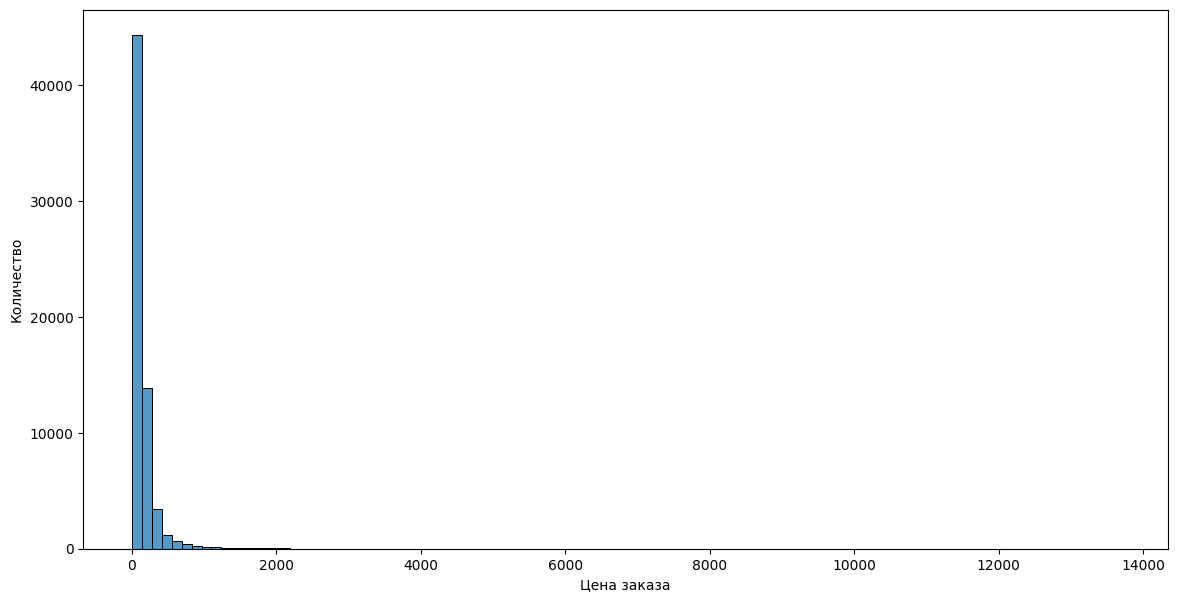

In [5]:
plt.figure(figsize=(14,7))
sns.histplot(data = four_states, x = 'order_value', bins = 100)
plt.xlabel('Цена заказа')
plt.ylabel('Количество')

<Axes: xlabel='Штат', ylabel='Цена заказа'>

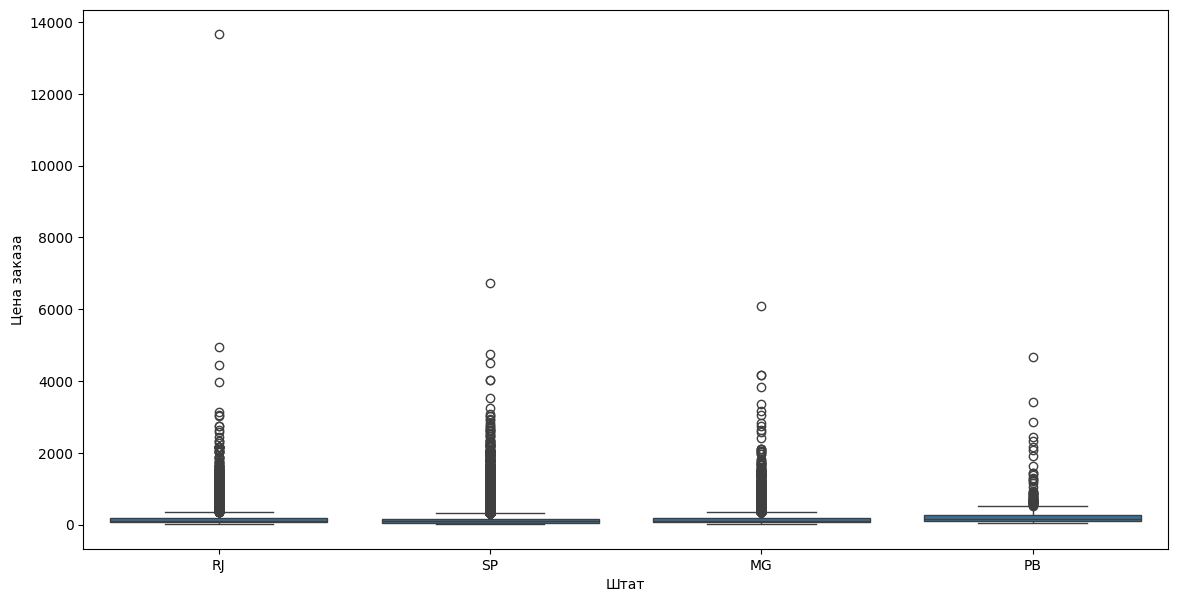

In [6]:
plt.figure(figsize=(14,7))
plt.ylabel('Цена заказа')
plt.xlabel('Штат')
sns.boxplot(data = four_states, y = 'order_value', x = 'customer_state')

EDA перед статистическим тестом: сумма заказа по 4 штатам (RJ, SP, MG, PB)

Гистограмма показывает сильный правый скос:
основная масса заказов — в диапазоне 0-500. Такая форма типична для денежных
величин и явно не соответствует нормальному
распределению.

Boxplot подтверждает эту картину:
у всех штатов много выбросов сверху,
межквартильные размахи выглядят похожими
между группами. У PB коробка чуть выше,
но выбросов заметно меньше — вероятно,
из-за маленькой выборки (517 заказов
против десятков тысяч у остальных).

Вывод: данные ненормальны и содержат
много выбросов, поэтому для сравнения групп
используем Kruskal-Wallis.

### Статистический тест: Kruskal-Wallis

**H0:** распределения order_value во всех четырёх штатах одинаковы (различия — случайность выборки).
**H1:** хотя бы в одном штате распределение значимо отличается.

α = 0.05.

In [ ]:
sp_values = four_states[four_states['customer_state'] == 'SP']['order_value']
rj_values = four_states[four_states['customer_state'] == 'RJ']['order_value']
mg_values = four_states[four_states['customer_state'] == 'MG']['order_value']
pb_values = four_states[four_states['customer_state'] == 'PB']['order_value']

kruskal_result = stats.kruskal(sp_values, rj_values, mg_values, pb_values)
kruskal_result

### Результат и вывод

`KruskalResult(statistic=805.82, pvalue=2.37e-174)`

p-value значительно меньше 0.05 → отклоняем H0. Различие в сумме заказа между
как минимум одной парой штатов статистически значимо, вероятность случайности
этого результата астрономически мала.

**Важный нюанс:** на boxplot межквартильные размахи между штатами визуально
выглядели похоже — сам по себе визуальный анализ не позволял сделать вывод
о значимости различий. При больших выборках (десятки тысяч наблюдений) даже
небольшие различия в распределениях становятся статистически значимыми —
поэтому формальный тест необходим, а не только визуальная оценка.

Kruskal-Wallis — omnibus-тест: он показывает, что различие где-то есть, но не
говорит, между какими именно парами штатов. Post-hoc анализ (попарные тесты
Манна-Уитни с поправкой на множественные сравнения) в этом проекте не
проводился — при желании это логичное продолжение анализа.